In [2]:
import os, sys, time, math, gc, mne, json
import torch
import json
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.signal as signal
from pathlib import Path
from inspect import signature
from enum import Enum
from sklearn.metrics import r2_score
from scipy.stats import zscore 
from scipy.spatial.distance import jensenshannon

from pn.feature_extraction import *
import pn.p5_utils as p5u

from corticom.core.highgamma import HighGammaExtractor, SpectralExtractor
from corticom.auxilary import xcog_lite, xplot

from intanutil import intan_rhd as intan


In [3]:
class  Outlist(Enum): 
    STATUS = int(0)
    TIME = int(1)
    SESSION = int(2)
    TTYPE =  int(3)
    LEVEL = int(4)
    STIME = int(5   )

SESSION_TIMES = np.asarray([22, 24+8.5, 24+12, 24+17, 24+19, 24+22, 48+10, 48+12, 48+18, 48+23, 72+9, 72+10])
SESSION_TIMES = SESSION_TIMES-SESSION_TIMES[0]

In [4]:
def pull_data_from_file(data_root, output_lists, trial_type, FAILURE_TIME_THRSH = 60):

    session = int(data_root[36])

    if("easy" in data_root) : level = "Easy"
    elif("medium" in data_root): level = "Medium"
    elif("hard" in data_root): level = "Hard"
    else:
        raise ValueError(f"The difficulty level is not valid.")

    if (not os.path.exists(os.path.join(data_root,'task_ui_events.jsonl'))):
        print( f'File {os.path.join(data_root,'task_ui_events.jsonl')} Does Not Exist')
        return
    with open( os.path.join(data_root,'task_ui_events.jsonl'), 'r') as json_file:
        json_list = list(json_file)

    t0 = None
    state = "REST"

    #try:
    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'target_initialized'):
                    match state:
                        case "REST":
                            t0 = result['microsecond']
                            state = "TRIAL"
                        case "TRIAL":
                            output_lists[Outlist.STATUS.value].append("FAIL")
                            output_lists[Outlist.TIME.value].append(-1)
                            output_lists[Outlist.SESSION.value].append(session)
                            output_lists[Outlist.TTYPE.value].append(trial_type)
                            output_lists[Outlist.LEVEL.value].append(level)
                            output_lists[Outlist.STIME.value].append(SESSION_TIMES[session])

                            t0 = result['microsecond']

                        case _: 
                            raise ValueError(f"The state {state} is not valid.")

                elif(result['data']['type'] == 'targets_complete'):
                    match state:
                        case "REST":
                            raise ValueError(f"SHOULD NOT BE IN REST")
                        case "TRIAL":
                            dt = (result['microsecond'] - t0)/1000000
                            if(dt < FAILURE_TIME_THRSH):
                                #print(session, type(session))
                                output_lists[Outlist.STATUS.value].append("SUCCESS")
                                output_lists[Outlist.TIME.value].append(dt)
                                output_lists[Outlist.SESSION.value].append(session)
                                output_lists[Outlist.TTYPE.value].append(trial_type)
                                output_lists[Outlist.LEVEL.value].append(level)
                                output_lists[Outlist.STIME.value].append(SESSION_TIMES[session])

                            else:
                                output_lists[Outlist.STATUS.value].append("FAIL")
                                output_lists[Outlist.TIME.value].append(dt)
                                output_lists[Outlist.SESSION.value].append(session)
                                output_lists[Outlist.TTYPE.value].append(trial_type)
                                output_lists[Outlist.LEVEL.value].append(level)
                                output_lists[Outlist.STIME.value].append(SESSION_TIMES[session])

                            t0 = None
                            state = "REST"
                        case _: 
                            raise ValueError(f"The state {state} is not valid.")
    if(output_lists[Outlist.STATUS.value][-1] == "FAIL"):
        output_lists[Outlist.STATUS.value].pop()
        output_lists[Outlist.TIME.value].pop()
        output_lists[Outlist.SESSION.value].pop()
        output_lists[Outlist.TTYPE.value].pop()
        output_lists[Outlist.LEVEL.value].pop()
        output_lists[Outlist.STIME.value].pop()
    #except:
    #    print("Issue Hit")        

In [5]:
subject_root = "D:\\Becca\\Data\\PN\\NSR-102-005\\"

train_block_id = {
            165: "Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_1_1767103993233_251230_141313\\",
            166: "Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_2_1767104299586_251230_141819",
            167: "Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_3_1767104515800_251230_142155",
            168: "Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_4_1767104746342_251230_142546",
            173: "Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_1_1767117086679_251230_175126",
            174: "Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_2_1767117317127_251230_175517",
            175: "Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_3_1767117503028_251230_175823",
            176: "Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_4_1767117701812_251230_180141",
            177: "Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_5_1767117907782_251230_180507",
            188: "Session4\\29-DEC-2025\\webgrid-easy_FIH0117_train_1_1767129389894_251230_211629",
            189: "Session4\\29-DEC-2025\\webgrid-easy_FIH0117_train_2_1767129551453_251230_211911",
            190: "Session4\\29-DEC-2025\\webgrid-easy_FIH0117_train_3_1767129740140_251230_212220",
            201: "Session5\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767139067812_251230_235747",
            203: "Session5\\29-DEC-2025\\webgrid-medium_FIH0117_train_3_1767139362911_251231_000242",
            211: "Session6\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767150443012_251231_030723",
            212: "Session6\\29-DEC-2025\\webgrid-medium_FIH0117_train_2_1767150632010_251231_031032",
            221: "Session7\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767192254968_251231_144414",
            222: "Session7\\29-DEC-2025\\webgrid-hard_FIH0117_train_2_1767192551361_251231_144911",
            226: "Session7\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767194331798_251231_151851",
            227: "Session7\\29-DEC-2025\\webgrid-medium_FIH0117_train_2_1767194526858_251231_152206",
            231: "Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767203809930_251231_175649",
            232: "Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_2_1767204034506_251231_180034",
            233: "Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_3_1767204239804_251231_180359",
            234: "Session8\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767204862210_251231_181422",
            235: "Session8\\29-DEC-2025\\webgrid-medium_FIH0117_train_2_1767205076652_251231_181756",
            252: "Session9\\29-DEC-2025\\webgrid-hard_FIH0117_train_3_1767222994808_251231_231634",
            253: "Session9\\29-DEC-2025\\webgrid-hard_FIH0117_train_4_1767223204299_251231_232004",
            254: "Session9\\29-DEC-2025\\webgrid-hard_FIH0117_train_5_1767223412173_251231_232332",
            }


infer_blocks = {
                169: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105022887_251230_143022\\",
                170: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105453895_251230_143733\\",
                178: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session3\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767118172455_251230_180932",
                191: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session4\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767129891132_251230_212451\\",
                205: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session5\\29-DEC-2025\\webgrid-medium_FIH0117_infer_2_1767140835594_251231_002715\\", #206
                213: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767151073946_251231_031753\\",  # Session 6 has some no joystick inf
                223: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session7\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767193180404_251231_145940\\", #minimal joystick use
                236: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767206977752_251231_184937\\",
                266: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-medium_FIH0117_infer_2_1767227281175_260101_002801\\"
}

nojoy_blocks = {

                215: 'D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-easy_FIH0117_infer_2_1767151847540_251231_033047\\',
                214: 'D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767151400299_251231_032320\\',
                
                237: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_2_1767207322061_251231_185522", # + hand movement
                238: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_3_1767207662584_251231_190102", # + hand movement
                239: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_4_1767207953029_251231_190553\\",

                259: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767224678966_251231_234438\\",
                260: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767226373838_260101_001253\\",
                261: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_2_1767225390165_251231_235630\\",
                262: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_3_1767225709295_260101_000149\\",
                263: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_4_1767226045714_260101_000725\\",
               
}

stale_blocks = {
        198: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session5\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767138083419_251230_234123\\",  # 200
        210: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767150106991_251231_030147\\",
        220: "D:\\Becca\\Data\\PN\\NSR-102-005\\Session7\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767191902811_251231_143822\\",
}


infer_train_sets =  {
                    169: [165,166,167],                                                 # S2
                    170: [165,166,167],                                                 # S2
                    178: [165,166,167,168,173,174],                                     # S3
                    179: [174,175,176,177],                                             # S3
                    191: [175, 176, 177, 188],                                          # S4
                    192: [175, 176, 177, 188, 189, 190],                                # S4
                    198: [174,175,176,177],                                             # S5, stale
                    204: [188, 189, 190, 198, 201, 203],                                # S5
                    205: [175, 176, 177, 188, 189, 190, 203],                           # S6
                    213: [177, 188, 189, 190, 201, 203, 211, 212],                      # S6
                    223: [177, 190, 201, 203, 211, 221, 222],                           # S7
                    236: [221, 222, 226, 227, 231, 232, 233, 234, 235],                 # S8
                    258: [221, 222, 226, 227, 231, 232, 233, 234, 235, 252, 253, 254],   # S9
                    266: [221, 222, 226, 227, 231, 232, 233, 234, 235, 252, 253, 254],   # S9

}

In [6]:
for block in p5u.infer_blocks:
    print(f'Inference {block} training time {p5u.get_inf_train_time(block)/60}min')
    print('-------------------------------------')

Inference 169 training time 8.548min
-------------------------------------
Inference 170 training time 8.548min
-------------------------------------
Inference 178 training time 16.7075min
-------------------------------------
Inference 191 training time 11.369666666666667min
-------------------------------------
Inference 205 training time 18.339833333333335min
-------------------------------------
Inference 213 training time 20.36733333333333min
-------------------------------------
Inference 223 training time 20.455333333333336min
-------------------------------------
Inference 236 training time 27.604666666666667min
-------------------------------------
Inference 266 training time 37.292833333333334min
-------------------------------------


In [7]:
def get_block_time(blockroot):
    try: 
        labeldata = torch.load(os.path.join(blockroot, "CursorJoystickCRNNImplementation","labels.pt") )
        return labeldata.shape[0] / 100
    except:
        print(f'Error with {blockroot}')

In [8]:
def get_inf_train_time(blocknum):
    training_time = 0
    for block in infer_train_sets[blocknum]:
        block_path = train_block_id[block]
        training_time += get_block_time(os.path.join(subject_root, block_path))
        #print(f'used block {block}, net time {training_time}s, {training_time/60}min')
    return training_time

In [9]:
def calc_results(FAILURE_TIME_THRSH = 60):

        status_list = []
        time_list = []
        session_list = []
        type_list = []
        level_list = []
        stime_list = []

        train_list = [
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_1_1767103993233_251230_141313\\",  #165
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session3\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_2_1767117317127_251230_175517\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session4\\29-DEC-2025\\webgrid-easy_FIH0117_train_1_1767129389894_251230_211629\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session5\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767139067812_251230_235747\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767150443012_251231_030723\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_train_1_1767150443012_251231_030723\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session7\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767192254968_251231_144414\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767203809930_251231_175649\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-hard_FIH0117_train_3_1767222994808_251231_231634\\",
                ]


        infer_list = [
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105022887_251230_143022\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105453895_251230_143733\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session3\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767118172455_251230_180932",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session4\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767129891132_251230_212451\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session5\\29-DEC-2025\\webgrid-medium_FIH0117_infer_2_1767140835594_251231_002715\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767151073946_251231_031753\\",  # Session 6 has some no joystick inf
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767151073946_251231_031753\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session7\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767193180404_251231_145940\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767206977752_251231_184937\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-medium_FIH0117_infer_2_1767227281175_260101_002801\\"
                ]


        nojoy_list = [
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-medium_FIH0117_infer_2_1767227281175_260101_002801\\",

                'D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-easy_FIH0117_infer_2_1767151847540_251231_033047\\',
                'D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767151400299_251231_032320\\',
                
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_2_1767207322061_251231_185522", # + hand movement
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_3_1767207662584_251231_190102", # + hand movement
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_4_1767207953029_251231_190553\\",

                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767224678966_251231_234438\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767226373838_260101_001253\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_2_1767225390165_251231_235630\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_3_1767225709295_260101_000149\\",
                "D:\\Becca\\Data\\PN\\NSR-102-005\\Session9\\29-DEC-2025\\webgrid-veasy_FIH0117_infer_4_1767226045714_260101_000725\\",
        ]

        oldmodel_list = [
        "D:\\Becca\\Data\\PN\\NSR-102-005\\Session5\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767138083419_251230_234123\\",
        "D:\\Becca\\Data\\PN\\NSR-102-005\\Session6\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767150106991_251231_030147\\",
        "D:\\Becca\\Data\\PN\\NSR-102-005\\Session7\\29-DEC-2025\\webgrid-medium_FIH0117_infer_1_1767191902811_251231_143822\\",
        ]


        for data_root in train_list:
                pull_data_from_file(    data_root, 
                                [status_list,
                                        time_list,
                                        session_list,
                                        type_list,
                                        level_list,
                                        stime_list ], 
                                        "TRAIN")
                
        for data_root in infer_list:
                pull_data_from_file(    data_root, 
                                [status_list,
                                        time_list,
                                        session_list,
                                        type_list,
                                        level_list,
                                        stime_list ], 
                                        "INFER")
        for data_root in nojoy_list:
                pull_data_from_file(data_root, 
                                [status_list,
                                        time_list,
                                        session_list,
                                        type_list,
                                        level_list,
                                        stime_list ], 
                                        "NO JOYSTICK")
                
        for data_root in oldmodel_list:
                pull_data_from_file(    data_root, 
                                [status_list,
                                        time_list,
                                        session_list,
                                        type_list,
                                        level_list,
                                        stime_list ], 
                                        "STALE MODEL")
        df = pd.DataFrame({
                        'Session': session_list,
                        'time': time_list,
                        'Block Type': type_list,
                        'status': status_list,
                        'Difficulty': level_list,
                        'Session Time': stime_list              
                        })
        df["Session"] = df["Session"].astype(int)
        return df


In [10]:
def plot_results(df,FAILURE_TIME_THRSH ):

    fig,ax = plt.subplots(1,2, figsize=(10,5))

    # Draw a nested violinplot and split the violins for easier comparison
    success_df = df[df['status'] == "SUCCESS"]

#success_rate
    test_count = []
    success_count = []
    level_list = []
    session_list = []
    for session in range(2,10): 
        temp_df = df[df["Session"] == session]
        test_count.append(np.sum(temp_df["Block Type"] == "TEST"))
        temp_df = temp_df [temp_df["Block Type"] == "TEST"]
        success_count.append(np.sum(temp_df["status"] == "SUCCESS"))
        session_list.append(session)
        try:
            row_num = temp_df.index.to_numpy()[0]
            level_list.append(temp_df['Difficulty'][row_num])
        except:
            level_list.append(None)


    summary_df = pd.DataFrame({
                            'Session': session_list,
                            'Success Count': success_count,
                            'Total Trials': test_count,
                            'Accuracy': np.asarray(success_count)/np.asarray(test_count),
                            'Difficulty': level_list
        })

   
    sns.scatterplot(data = summary_df, 
                x="Session", 
                y="Accuracy",
                hue="Difficulty",
                ax=ax[0])

    ax[0].set_title(f'Completion Rate Across Sessions(cutoff = {FAILURE_TIME_THRSH}s )')
    ax[0].set_ylim(0,1.1)


    #---------------------------------



    sns.violinplot(data=success_df, x="Session", y="time", hue="Block Type",
                split=True, inner="quart", cut= 0, bw_adjust = 0.3, fill=False, ax=ax[1])
    ax[1].set_title(f'Completion Time For Successful Trials')
    ax[1].set_ylabel("Time(s)")

    #---------------------------------
    

In [11]:
def calc_success_rate(df):
    test_count = []
    success_count = []
    level_list = []
    session_list = []
    stime_list = []
    for session in range(2,10): 
        for btype in ["INFER","NO JOYSTICK", "STALE MODEL"]:
            temp_df = df[df["Session"] == session]
            test_count.append(np.sum(temp_df["Block Type"] == btype))
            temp_df = temp_df[temp_df["Block Type"] == btype]

            success_count.append(np.sum(temp_df["status"] == "SUCCESS"))
            session_list.append(session)
            print(f'Session {session} Block {btype}, {success_count[-1]}/{test_count[-1]}')

            try:
                row_num = temp_df.index.to_numpy()[0]

                match btype:
                    case "INFER":
                       # level_list.append(temp_df['Difficulty'][row_num])
                        level_list.append(temp_df['Block Type'][row_num])

                        stime_list.append(temp_df['Session Time'][row_num])
                    case "NO JOYSTICK":
                        level_list.append(temp_df['Block Type'][row_num])
                        stime_list.append(temp_df['Session Time'][row_num]+1)
                    case "STALE MODEL":
                        level_list.append(temp_df['Block Type'][row_num])
                        stime_list.append(temp_df['Session Time'][row_num]+2)

            except:
                level_list.append(None)
                stime_list.append(None)

    summary_df = pd.DataFrame({
                            'Session': session_list,
                            'Success Count': success_count,
                            'Total Trials': test_count,
                            'Accuracy': np.asarray(success_count)/np.asarray(test_count),
                            'Difficulty': level_list,
                            'Session Time': stime_list
        })
    return summary_df

 # A Composite Graph


Session 2 Block INFER, 11/16
Session 2 Block NO JOYSTICK, 0/0
Session 2 Block STALE MODEL, 0/0
Session 3 Block INFER, 0/0
Session 3 Block NO JOYSTICK, 0/0
Session 3 Block STALE MODEL, 0/0
Session 4 Block INFER, 26/27
Session 4 Block NO JOYSTICK, 0/0
Session 4 Block STALE MODEL, 0/0
Session 5 Block INFER, 30/30
Session 5 Block NO JOYSTICK, 0/0
Session 5 Block STALE MODEL, 25/25
Session 6 Block INFER, 32/32
Session 6 Block NO JOYSTICK, 35/36
Session 6 Block STALE MODEL, 17/18
Session 7 Block INFER, 14/16
Session 7 Block NO JOYSTICK, 0/0
Session 7 Block STALE MODEL, 21/22
Session 8 Block INFER, 35/35
Session 8 Block NO JOYSTICK, 8/11
Session 8 Block STALE MODEL, 0/0
Session 9 Block INFER, 28/28
Session 9 Block NO JOYSTICK, 87/95
Session 9 Block STALE MODEL, 0/0


C:\Users\Becca\AppData\Local\Temp\ipykernel_41764\1024987175.py:41: RuntimeWarning: invalid value encountered in divide
  'Accuracy': np.asarray(success_count)/np.asarray(test_count),


Median Completion Time Values
                     median     iqr    mean     std    n
Session Block Type                                      
2       INFER        10.607  15.838  16.382  12.135   11
        TRAIN         2.109   1.112   2.234   0.796   74
3       TRAIN         2.019   0.807   2.016   0.601   75
4       INFER         5.732   6.935   8.645   7.647   25
        TRAIN         1.680   0.693   1.617   0.549   75
5       INFER         8.289   5.091   8.725   5.023   29
        STALE MODEL   5.187   6.521   9.491   9.751   25
        TRAIN         2.049   0.712   2.051   0.468   73
6       INFER        10.024  20.491  15.144  11.525   32
        NO JOYSTICK   8.160   8.728  10.685   8.432   34
        STALE MODEL   7.138   9.173   9.147   6.211   16
        TRAIN         2.082   0.855   2.104   0.556  148
7       INFER         6.860   4.509   7.482   4.152   13
        STALE MODEL   7.151   6.536   8.205   5.321   20
        TRAIN         2.672   1.033   2.629   0.724   75
8

[]

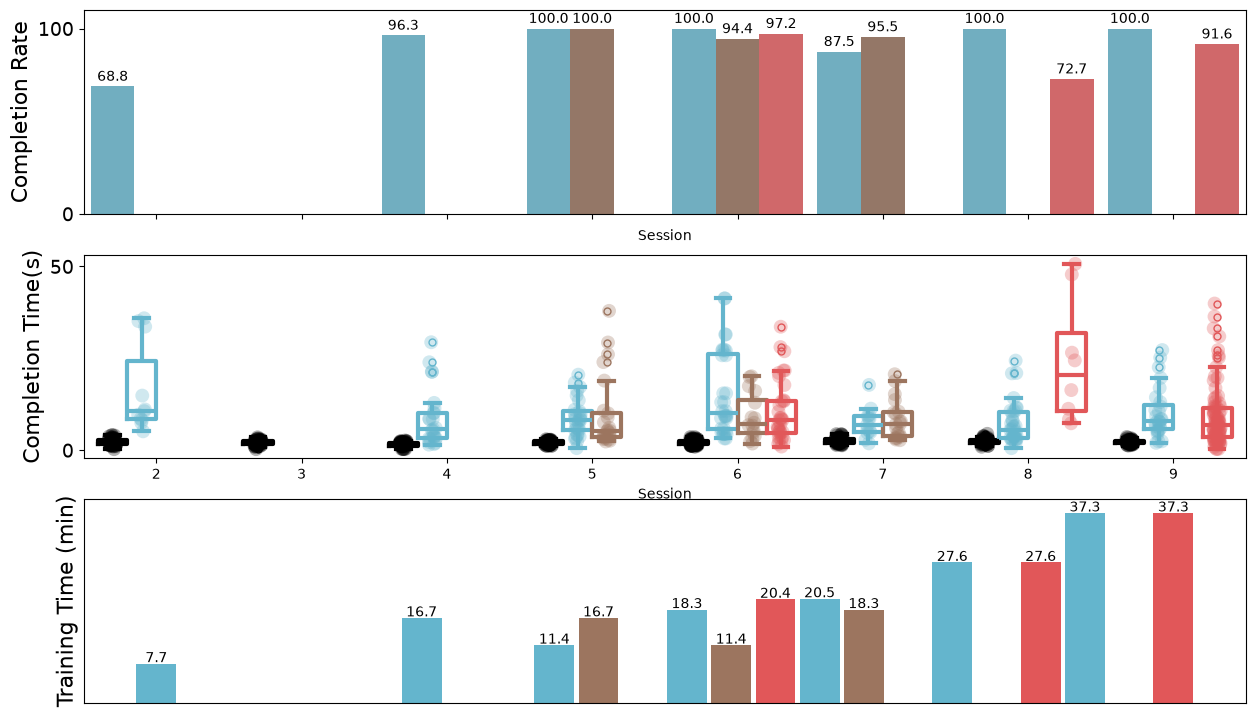

In [14]:
res_df = calc_results(FAILURE_TIME_THRSH = 50)


#-----------------------------
fig,ax = plt.subplots(3,1, figsize = (15,9))


#--------------------
summary_df = calc_success_rate(res_df)

sns.barplot(data = summary_df, 
            x="Session",
            y="Accuracy",
            hue="Difficulty",
            width=0.9,
            palette = {
                'INFER':    '#64B5CD',        # light blue
                #'Medium':   '#00A6D6',     # =
                'NO JOYSTICK':  '#E15759',        
                'STALE MODEL':  '#9C755F' 
            
            },
            # style = "Difficulty",
           # markers = {"Easy": 'o',
           #            "Medium": 'o',
           #            "STALE MODEL": 's',
           #            "NO JOYSTICK":'s'},
            ax=ax[0],
            legend=False,
           # s=200
            )

#ax[1].set_title(f'Task Completion Rate')
ax[0].set_ylabel("Completion Rate",fontsize=16)
ax[0].set_ylim(0,1.1)
ax[0].set_xticklabels([])
ax[0].set_yticks([0,1])
ax[0].set_yticklabels([0,100], fontsize=14)


for bar in ax[0].patches:
    height = bar.get_height()
    ax[0].text(
    bar.get_x() + bar.get_width() / 2,
    height+0.05,                  # inside the bar
    f'{np.round(100*height,1)}',
    ha='center',
    va='center',
    color='black',
    fontsize=10
    )

#--------------------
success_df = res_df[res_df['status'] == "SUCCESS"]

df_list = []
for session in range(2,10):
    for blocktype in ["TRAIN", "INFER", "STALE MODEL", "NO JOYSTICK"]:
        sesh_type_df = success_df[(success_df["Session"] == session) & (success_df["Block Type"] == blocktype)]
        #print(f'Session {session} {blocktype}, {len(sesh_type_df)} trials')
        sesh_type_df = sesh_type_df[(np.abs(zscore(sesh_type_df["time"])) < 3)]
        df_list.append(sesh_type_df)

clean_df = pd.concat(df_list)

'''
sns.violinplot(data=all_df[all_df['Block Type'] == "TRAIN"],
            y="Subject", 
            order=["P3", "P4", "P5"], 
            x="time", 
            hue="Subject",
            palette={
            'P3': color_set[2],
            'P4': color_set[3],
            "P5": color_set[4]
            },
            split=True, 
            inner="quart", 
            cut= 0, 
            bw_adjust = 0.3, 
            fill=True, 
            ax=ax[1], 
            linewidth=5, 
            scale='width')
'''
sns.stripplot(data=clean_df,
               x="Session",
               y="time",
               hue="Block Type",
               palette= {
                'TRAIN': "black", 
                'INFER':    '#64B5CD',        # light blue
                'NO JOYSTICK':  '#E15759',        
                'STALE MODEL':  '#9C755F' 
               },
               alpha=0.3,
               legend=False,
               dodge=True,
               s=10,
               ax=ax[1],
                )
time_boxes = sns.boxplot(data=clean_df,
               x="Session",
               y="time",
               hue="Block Type",
               palette= {
                'TRAIN': "black", 
                'INFER':    '#64B5CD',        # light blue
                'NO JOYSTICK':  '#E15759',        
                'STALE MODEL':  '#9C755F' 
               },
               legend=False,
               dodge=True,
               fill= False,
               fliersize=5,
               ax=ax[1],
               linewidth=3,
              
                )
               #scale='width',
                #split=True, inner="quart", cut= 0, bw_adjust = 0.3, fill=False, legend=False)
medians = (
    clean_df
    .groupby(["Session", "Block Type"], observed=True)["time"]
    .median()
)
stats = (
    clean_df
    .groupby(["Session", "Block Type"], observed=True)["time"]
    .agg(
        median="median",
        iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
        mean="mean",
        std="std",
        n="count",
    )
)

print("Median Completion Time Values")
#print(medians.unstack("Block Type").round(3))#ax[2].set_title(f'Completion Time For Successful Trials')
print(stats.round(3))
ax[1].set_ylabel("Completion Time(s)", fontsize=16)
ax[1].set_yticks([0,50])
ax[1].set_yticklabels([0,50], fontsize=14)
#----------------------------------------------------

ax[2].set_ylabel('Training Time (min)', fontsize=16)

inf_comp_rate = [57.9, 96.3, 100,100, 87.5, 100.0, 100.0]
inf_times =            [7.73, 16.71,11.37, 18.34, 20.46, 27.60, 37.29]
inf_sesh = np.asarray([ 2,      4,    5,      6,    7,    8,     9])

stale_comp_rate = [100, 94.4, 95.5]
stale_times = [16.71, 11.37, 18.34]
stale_sesh = np.asarray([5,6,7])
nojoy_times = [20.37, 27.60, 37.29]
nojoy_sesh = np.asarray([6,8,9])

ax[2].bar(3*inf_sesh, inf_times, width=0.9, color="#64B5CD" )
ax[2].bar(3*stale_sesh + 1, stale_times,width=0.9, color="#9C755F" )
ax[2].bar(3*nojoy_sesh+2, nojoy_times,width=0.9, color="#E15759" )


for bar in ax[2].patches:
    height = bar.get_height()
    ax[2].text(
    bar.get_x() + bar.get_width() / 2,
    height+1,                  # inside the bar
    f'{np.round(height,1)}',
    ha='center',
    va='center',
    color='black',
    fontsize=10
    )
ax[2].set_ylim([0,40])
ax[2].set_yticks([])
ax[2].set_xticks([])